# International metropolitan areas from city data

In [31]:
from pathlib import Path
import sys, platform
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans, DBSCAN, AgglomerativeClustering
from sklearn.neighbors import BallTree
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score, adjusted_rand_score, normalized_mutual_info_score, balanced_accuracy_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.svm import SVC
from IPython.display import display
SEED = 42
EARTH_KM = 6371.0088
INPUT = Path('msa.csv')
OUTPUT = Path('msa_output.csv')
assert INPUT.exists(), 'Put msa.csv beside this notebook, then run all cells.'
print('Python:', platform.python_version())
import sklearn
print('scikit-learn:', sklearn.__version__)


Python: 3.14.3
scikit-learn: 1.7.2


## 1. Cleaning API

In [ ]:
class DataCleaningAPI:
    required = ['city', 'state', 'country', 'latitude', 'longitude', 'population', 'msa']
    def clean(self, source):
        raw = pd.read_csv(source)
        missing = set(self.required) - set(raw.columns)
        if missing: raise ValueError(f'Missing columns: {sorted(missing)}')
        d = raw[self.required].copy()
        d['row_id'] = np.arange(len(d))
        for col in ['city', 'state', 'country']:
            d[col + '_key'] = d[col].fillna('').astype(str).str.strip().str.casefold()
        for col in ['latitude', 'longitude', 'population']:
            d[col] = pd.to_numeric(d[col], errors='coerce')
        bad_pop = ~np.isfinite(d.population) | (d.population < 0)
        #print(f'type of bad_pop: {type(bad_pop)}, shape: {bad_pop.shape}, sum: {bad_pop.sum()}, bad_pop: {bad_pop}')
        d.loc[bad_pop, 'population'] = np.nan
        d['geo_valid'] = (d.latitude.between(-90, 90) & d.longitude.between(-180, 180)
                          & d.country_key.ne('') & d.city_key.ne('')) # .ne is equivalent to !=; geova;id check if the loc is vaild or not based on lat/ log
        identity = ['city_key', 'state_key', 'country_key', 'latitude', 'longitude', 'population']
        d['model_id'] = d.groupby(identity, dropna=False, sort=False).ngroup()
        self.audit = pd.Series({
            'input_rows': len(d), 'invalid_geography_or_identity': int((~d.geo_valid).sum()),
            'unknown_or_invalid_population': int(d.population.isna().sum()),
            'duplicate_observations': int(d.duplicated(identity).sum()),
            'repeated_city_state_country': int(d.duplicated(['city_key','state_key','country_key']).sum()),
            'missing_traditional_labels': int(d.msa.isna().sum())})
        self.rows = d
        return d.drop_duplicates('model_id').reset_index(drop=True)
    @staticmethod
    def transform(d):
        radians = np.radians(d[['latitude','longitude']].to_numpy(float))
        lat, lon = radians.T
        xyz = EARTH_KM * np.column_stack([np.cos(lat)*np.cos(lon), np.cos(lat)*np.sin(lon), np.sin(lat)])
        return {'radians': radians, 'xyz_km': xyz,
                'log_population': np.log1p(d.population.to_numpy(float))}

cleaner = DataCleaningAPI()
cities = cleaner.clean(INPUT)
display(cleaner.audit.to_frame('count'))
display(cities.head())


type of bad_pop: <class 'pandas.core.series.Series'>, shape: (25410,), sum: 0, bad_pop: 0        False
1        False
2        False
3        False
4        False
         ...  
25405    False
25406    False
25407    False
25408    False
25409    False
Name: population, Length: 25410, dtype: bool


,count
input_rows,25410
invalid_geography_or_identity,0
unknown_or_invalid_population,0
duplicate_observations,0
repeated_city_state_country,0
missing_traditional_labels,18383


,city,state,country,latitude,longitude,population,msa,row_id,city_key,state_key,country_key,geo_valid,model_id
0,mahopac,new york,united states,41.37232,-73.73346,8369.0,New York-Northern New Jersey-Long Island NY-NJ...,0,mahopac,new york,united states,True,0
1,seven hills,ohio,united states,41.39533,-81.67624,11690.0,NaN,1,seven hills,ohio,united states,True,1
2,new martinsville,west virginia,united states,39.64452,-80.85760,5218.0,WV NONMETROPOLITAN AREA,2,new martinsville,west virginia,united states,True,2
3,sint anthonis,north brabant,netherlands,51.62667,5.88194,3340.0,NaN,3,sint anthonis,north brabant,netherlands,True,3
4,machali,o higgins region,chile,-34.18082,-70.64933,27595.0,NaN,4,machali,o higgins region,chile,True,4


## 2. EDA: coverage, population, missingness and geography

,missing
city,0
state,21
country,0
latitude,0
longitude,0
population,0
msa,18383


,population
count,2.541000e+04
mean,1.023897e+05
std,6.321256e+05
min,0.000000e+00
50%,1.406300e+04
90%,1.400000e+05
95%,3.238171e+05
99%,1.539119e+06
max,4.125216e+07


,cities
country_key,
united states,7484
france,2341
united kingdom,1398
italy,1114
australia,1006
germany,979
netherlands,965
brazil,952
india,868


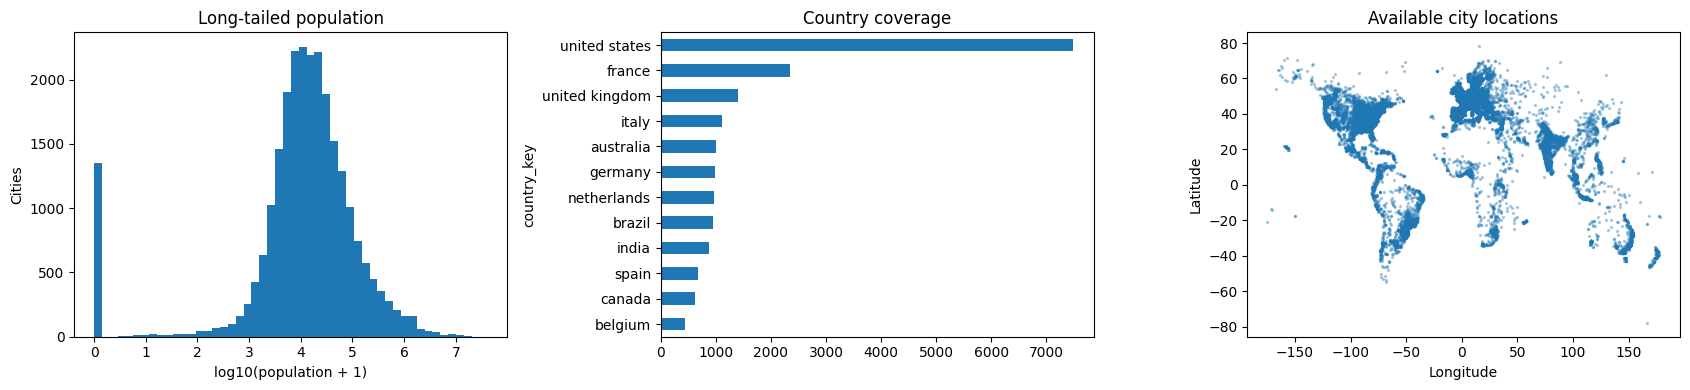

US cities: 7484 Traditional-label coverage: 0.9274452164617851


,cities
msa,
New York-Northern New Jersey-Long Island NY-NJ-PA MSA,526
Chicago-Naperville-Joliet IL-IN-WI MSA,200
Philadelphia-Camden-Wilmington PA-NJ-DE-MD MSA,195
Boston-Cambridge-Quincy MA-NH MSA,166
Los Angeles-Long Beach-Santa Ana CA MSA,157
Washington-Arlington-Alexandria DC-VA-MD-WV MSA,111
TX NONMETROPOLITAN AREA,101
Detroit-Warren-Livonia MI MSA,91
NC NONMETROPOLITAN AREA,90


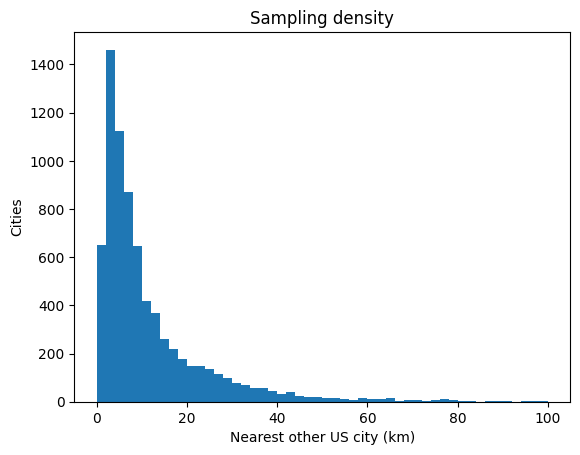

In [ ]:
display(cleaner.rows[cleaner.required].isna().sum().to_frame('missing'))
display(cities.population.describe(percentiles=[.5,.9,.95,.99]).to_frame())
display(cities.country_key.value_counts().head(15).to_frame('cities'))
fig, ax = plt.subplots(1,3,figsize=(17,4))
ax[0].hist(np.log10(cities.population.dropna()+1), bins=50) #log10(population + 1) to avoid log(0) issues
ax[0].set(xlabel='log10(population + 1)', ylabel='Cities', title='Long-tailed population')
cities.country_key.value_counts().head(12).sort_values().plot.barh(ax=ax[1], title='Country coverage')
g = cities[cities.geo_valid]
ax[2].scatter(g.longitude,g.latitude,s=2,alpha=.3)
ax[2].set(xlabel='Longitude',ylabel='Latitude',title='Available city locations')
plt.tight_layout(); plt.show()
us = cities[cities.geo_valid & cities.country_key.eq('united states')].copy()
traditional = us.msa.fillna('').str.strip()
print('US cities:', len(us), 'Traditional-label coverage:', traditional.ne('').mean())
display(traditional[traditional.ne('')].value_counts().head(12).to_frame('cities'))
features = cleaner.transform(us)
# Exclude self; geographic nearest-neighbor distance illustrates sampling density.
dist, _ = BallTree(features['radians'], metric='haversine').query(features['radians'], k=2)
plt.hist(dist[:,1]*EARTH_KM, bins=np.linspace(0,100,51))
plt.xlabel('Nearest other US city (km)'); plt.ylabel('Cities'); plt.title('Sampling density'); plt.show()


## 3. Processing API and baseline models

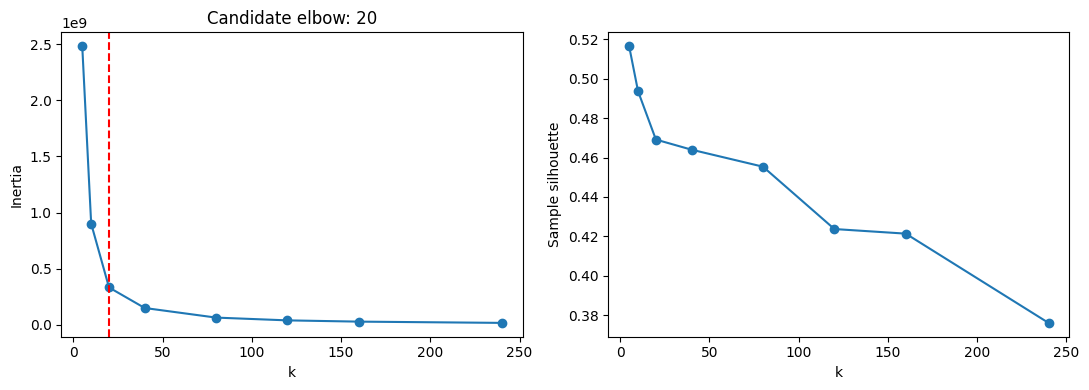

,k,inertia,silhouette
0,5,2.482157e+09,0.516527
1,10,9.017652e+08,0.493664
2,20,3.336283e+08,0.469114
3,40,1.508900e+08,0.463970
4,80,6.545186e+07,0.455347
5,120,4.067803e+07,0.423700
6,160,2.954977e+07,0.421362
7,240,1.834695e+07,0.376059


In [ ]:
US_ABBR = {'alabama':'AL','alaska':'AK','arizona':'AZ','arkansas':'AR','california':'CA','colorado':'CO',
 'connecticut':'CT','delaware':'DE','florida':'FL','georgia':'GA','hawaii':'HI','idaho':'ID','illinois':'IL',
 'indiana':'IN','iowa':'IA','kansas':'KS','kentucky':'KY','louisiana':'LA','maine':'ME','maryland':'MD',
 'massachusetts':'MA','michigan':'MI','minnesota':'MN','mississippi':'MS','missouri':'MO','montana':'MT',
 'nebraska':'NE','nevada':'NV','new hampshire':'NH','new jersey':'NJ','new mexico':'NM','new york':'NY',
 'north carolina':'NC','north dakota':'ND','ohio':'OH','oklahoma':'OK','oregon':'OR','pennsylvania':'PA',
 'rhode island':'RI','south carolina':'SC','south dakota':'SD','tennessee':'TN','texas':'TX','utah':'UT',
 'vermont':'VT','virginia':'VA','washington':'WA','washington d c':'DC','west virginia':'WV',
 'wisconsin':'WI','wyoming':'WY'}

def haversine_km(a, b):
    """Great-circle distance between [lat, lon] arrays (degrees); broadcasts."""
    a, b = np.radians(a), np.radians(b)
    h = (np.sin((b[..., 0]-a[..., 0])/2)**2
         + np.cos(a[..., 0])*np.cos(b[..., 0])*np.sin((b[..., 1]-a[..., 1])/2)**2)
    return 2*EARTH_KM*np.arcsin(np.sqrt(np.clip(h, 0, 1)))

def nice(s):
    return str(s).title()

class DataProcessingAPI:
    def kmeans(self, d, k):
        x = DataCleaningAPI.transform(d)['xyz_km']
        model = KMeans(n_clusters=k, n_init=10, random_state=SEED).fit(x)
        return model, model.labels_

    def dbscan(self, d, eps_km=25, min_samples=5):
        x = DataCleaningAPI.transform(d)['radians']
        return DBSCAN(eps=eps_km/EARTH_KM, min_samples=min_samples,
                      metric='haversine', algorithm='ball_tree').fit_predict(x)

    @staticmethod
    def reach(pop, core, base_km, exponent, max_km):
        # calculate adaptive reach of a metro based on its population and the core population threshold
        return np.minimum(base_km*(np.maximum(pop, core)/core)**exponent, max_km)

    def metros(self, d, core_population=50000, base_km=20, exponent=0.3, max_km=80,
               satellite_km=12, local_km=10, dup_km=2, rural_km=80, labels=True):
        if min(core_population, base_km, max_km, satellite_km, rural_km) <= 0:
            raise ValueError('Thresholds must be positive')
        out = d.copy()
        out['metro_id'] = pd.Series(None, index=out.index, dtype=object)
        out['rural_id'] = pd.Series(None, index=out.index, dtype=object)
        out['anchor_distance_km'] = np.nan
        out['seed'] = False
        for country, g in out[out.geo_valid].groupby('country_key', sort=True):
            g = g.sort_values(['population', 'city_key', 'state_key', 'latitude', 'longitude'],
                              ascending=[False, True, True, True, True], na_position='last') #na= last to ensure that cities with unknown population are at the end of the list
            xy = g[['latitude', 'longitude']].to_numpy(float)
            pop = np.nan_to_num(g.population.to_numpy(float))      # unknown population cannot seed
            # 1. Seeds: a large city, or the largest city of a dense local cluster.
            nb = BallTree(np.radians(xy), metric='haversine').query_radius(np.radians(xy), r=local_km/EARTH_KM) # nb is nearby cities within local_km of each city
            local = np.array([pop[j].sum() for j in nb])
            peak = np.array([pop[i] >= pop[j].max() for i, j in enumerate(nb)])
            seeds = np.flatnonzero((pop >= core_population) | ((local >= core_population) & peak & (pop > 0)))
            ids = np.full(len(g), -1)
            if len(seeds):
                # 2. Urban cores: seeds linked within satellite_km (largest seed first).
                comp = DBSCAN(eps=satellite_km/EARTH_KM, min_samples=1,
                              metric='haversine').fit_predict(np.radians(xy[seeds]))
                cores = []
                for c in np.unique(comp):
                    idx = seeds[comp == c] #idx hold the indices of the cities in the current core
                    # Overlapping records (a city and its districts, duplicate spellings)
                    # are common; a seed within dup_km of a larger one adds no population.
                    p = sum(pop[i] for k, i in enumerate(idx)
                            if k == 0 or haversine_km(xy[i][None], xy[idx[:k]]).min() > dup_km) # don't add overlapping population inside the same core
                    cores.append((p, idx))
                cores.sort(key=lambda t: (-t[0], t[1][0]))
                # 3. Metros: a core joins the strongest metro whose reach covers it.
                anchors, mpop, members = [], [], []
                for p, idx in cores:
                    a, best, best_score = xy[idx[0]], None, -1.0
                    for m in range(len(anchors)):
                        da = haversine_km(a, anchors[m])
                        if da <= self.reach(mpop[m], core_population, base_km, exponent, max_km):
                            score = mpop[m]/max(da, 1)**2
                            if score > best_score: best, best_score = m, score
                    if best is None:
                        anchors.append(a); mpop.append(p); members.append(list(idx)); best = len(anchors)-1
                    else:
                        mpop[best] += p; members[best].extend(idx)
                    ids[idx] = best
                # 4. Assign every other city by gravity among metros that reach it.
                A, P = np.array(anchors), np.array(mpop)
                R = self.reach(P, core_population, base_km, exponent, max_km)
                D = haversine_km(xy[:, None, :], A[None, :, :])
                near = np.column_stack([haversine_km(xy[:, None, :], xy[mem][None]).min(1) for mem in members])
                ok = ((D <= R) | (near <= satellite_km)) & (D <= max_km)
                score = np.where(ok, P/np.maximum(D, 1)**2, -1)
                is_seed = ids >= 0
                out.loc[g.index, 'seed'] = is_seed
                ids = np.where(is_seed, ids, np.where(score.max(1) > 0, score.argmax(1), -1))
                out.loc[g.index, 'anchor_distance_km'] = np.where(ids >= 0, D[np.arange(len(g)), np.maximum(ids, 0)], np.nan)
            out.loc[g.index, 'metro_id'] = [f'{country}#{m}' if m >= 0 else None for m in ids]
        out['metro'] = out.metro_id.notna()
        # 5. Non-metro regions: compact clusters (complete linkage, max span rural_km)
        #    within one country and state, so rural areas are explicit entities.
        rural = out[out.geo_valid & ~out.metro]
        for (c, s), g in rural.groupby(['country_key', 'state_key'], sort=True):
            if len(g) == 1:
                lab = [0]
            else:
                xy = g[['latitude', 'longitude']].to_numpy(float)
                lab = AgglomerativeClustering(n_clusters=None, metric='precomputed', linkage='complete',
                        distance_threshold=rural_km).fit_predict(haversine_km(xy[:, None, :], xy[None, :, :]))
            out.loc[g.index, 'rural_id'] = [f'{c}|{s}|{l}' for l in lab]
        out['Area Type'] = np.select([out.metro, out.geo_valid], ['Metro', 'Non-metro'], 'Review')
        if labels:
            out['Your MSA'] = self.label(out)
        return out

    @staticmethod
    def label(out):
        """Readable names: up to three distinct principal cities plus state codes or country."""
        names = {}
        for mid, g in out[out.metro].groupby('metro_id'):
            g = g.sort_values('population', ascending=False)
            top, named = g.iloc[0], [g.iloc[0]]
            for _, r in g.iloc[1:].iterrows():
                if len(named) == 3 or not r.population >= top.population/3: break
                # skip districts / duplicate records sitting inside an already-named city
                if all(haversine_km(np.array([r.latitude, r.longitude]), np.array([n.latitude, n.longitude])) >= 10
                       for n in named):
                    named.append(r)
            cities = '–'.join(nice(n.city_key) for n in named)
            if top.country_key == 'united states':
                states = g.groupby('state_key').population.sum().sort_values(ascending=False).index[:4]
                names[mid] = f"{cities}, {'-'.join(US_ABBR.get(s, nice(s)) for s in states)} Metro"
            else:
                names[mid] = f'{cities}, {nice(top.country_key)} Metro'
        for rid, g in out[out.rural_id.notna()].groupby('rural_id'):
            top = g.sort_values('population', ascending=False).iloc[0]
            place = (US_ABBR.get(top.state_key, nice(top.state_key)) if top.country_key == 'united states'
                     else ', '.join(nice(x) for x in [top.state_key, top.country_key] if x))
            names[rid] = f'Non-metro {place} – {nice(top.city_key)}' + (' area' if len(g) > 1 else '')
        key = out.metro_id.where(out.metro, out.rural_id)
        labels = key.map(names)
        # Same name for different entities (e.g. two Taizhous in China): add the region.
        series = pd.Series(names)
        for k in series[series.duplicated(keep=False)].index:
            region = nice(out.loc[key.eq(k)].sort_values('population').state_key.iloc[-1])
            labels[key.eq(k)] = (names[k].replace(' Metro', f' ({region}) Metro') if '#' in k
                                 else f'{names[k]} ({k.rsplit("|", 1)[-1]})')
        review = 'Review required | row ' + out.row_id.astype(str)
        return labels.where(key.notna(), review)

def agreement(df, label_col='Your MSA'):
    """Descriptive agreement with the noisy US labels (not ground truth)."""
    t = df.msa.fillna('').str.strip()
    known = t.ne('')
    official_metro = known & ~t.str.contains('NONMETROPOLITAN', case=False)
    lab = df[label_col].astype(str)
    return {'metro_status_agreement': (df.metro[known] == official_metro[known]).mean(),
            'ARI_on_official_metros': adjusted_rand_score(t[official_metro], lab[official_metro]),
            'purity': pd.crosstab(lab[official_metro], t[official_metro]).max(1).sum()/official_metro.sum(),
            'completeness': pd.crosstab(t[official_metro], lab[official_metro]).max(1).sum()/official_metro.sum(),
            'metros': lab[df.metro].nunique(), 'non_metro_regions': lab[~df.metro].nunique(),
            'metro_population_share': df.population[df.metro].sum()/df.population.sum()}

processor = DataProcessingAPI()
ks = [5,10,20,40,80,120,160,240]
km_rows = []
for k in ks:
    if k >= len(us): continue
    model, labels = processor.kmeans(us,k)
    assert np.isfinite(model.inertia_) and np.isfinite(model.cluster_centers_).all()
    score = silhouette_score(features['xyz_km'],labels,sample_size=min(1500,len(us)),random_state=SEED)
    km_rows.append({'k':k,'inertia':model.inertia_,'silhouette':score})
km_results = pd.DataFrame(km_rows)
# Max distance from the endpoint line in normalized k/inertia coordinates.
x = (km_results.k-km_results.k.min())/(km_results.k.max()-km_results.k.min())
y = (km_results.inertia-km_results.inertia.min())/(km_results.inertia.max()-km_results.inertia.min())
elbow_k = int(km_results.loc[np.argmax((1-x)-y),'k'])
fig,ax = plt.subplots(1,2,figsize=(11,4))
ax[0].plot(km_results.k,km_results.inertia,'o-'); ax[0].axvline(elbow_k,color='red',linestyle='--')
ax[0].set(xlabel='k',ylabel='Inertia',title=f'Candidate elbow: {elbow_k}')
ax[1].plot(km_results.k,km_results.silhouette,'o-'); ax[1].set(xlabel='k',ylabel='Sample silhouette')
plt.tight_layout(); plt.show(); display(km_results)

In [35]:
db_rows = []
for eps in [10,25,40,60]:
    for minimum in [3,5,10]:
        labels = processor.dbscan(us,eps,minimum)
        db_rows.append({'eps_km':eps,'min_samples':minimum,
                        'clusters':len(set(labels)-{-1}),'noise_fraction':float((labels==-1).mean())})
display(pd.DataFrame(db_rows))


,eps_km,min_samples,clusters,noise_fraction
0,10,3,306,0.470337
1,10,5,108,0.618920
2,10,10,29,0.803314
3,25,3,235,0.171833
4,25,5,142,0.255211
5,25,10,60,0.434928
6,40,3,120,0.066809
7,40,5,92,0.117317
8,40,10,64,0.228087
9,60,3,53,0.029530


### SVM diagnostic

In [36]:
from sklearn.impute import SimpleImputer
labeled = us[us.msa.fillna('').str.strip().ne('')].copy()
y = (~labeled.msa.str.contains('NONMETROPOLITAN',case=False,na=False)).astype(int)
x = np.column_stack([DataCleaningAPI.transform(labeled)['xyz_km'], np.log1p(labeled.population)])
if y.nunique() == 2 and y.value_counts().min() >= 5:
    x_train,x_test,y_train,y_test = train_test_split(x,y,test_size=.25,stratify=y,random_state=SEED)
    svm = make_pipeline(SimpleImputer(strategy='median'), StandardScaler(),
                        SVC(C=1,kernel='rbf',class_weight='balanced'))
    svm.fit(x_train,y_train)
    print('SVM noisy-label balanced accuracy (optimistic random split):',
          round(balanced_accuracy_score(y_test,svm.predict(x_test)),3))
else:
    print('SVM skipped: insufficient examples in both classes.')


SVM noisy-label balanced accuracy (optimistic random split): 0.726


## 4. Final model: calibration and sensitivity
Defaults core population 50,000; reach = 20 km × (P/50k)^0.3, capped at 80 km; seeds within 12 km form one urban core; local clusters measured within 10 km; rural regions at most 80 km across.

The grid below scores each setting against the noisy US labels:
- **ARI**: overall agreement of the groupings.
- **Purity**: does each of our metros sit inside one official MSA?
- **Completeness**: is each official MSA kept together?
- **Metro-status agreement**: do we and the official labels agree on metro vs. non-metro?

In [37]:
grid = []
for core in [25000, 50000, 100000]:
    for base in [15, 20, 25]:
        for ex in [0.25, 0.3, 0.35]:
            for cap in [80, 100]:
                if (core != 50000 and (base, ex, cap) != (20, 0.3, 80)) or (cap == 100 and (base, ex) != (20, 0.3)):
                    continue
                r = processor.metros(us, core_population=core, base_km=base, exponent=ex, max_km=cap)
                grid.append({'core_population': core, 'base_km': base, 'exponent': ex, 'max_km': cap, **agreement(r)})
fixed = processor.metros(us, base_km=40, exponent=0.0, max_km=40)
grid.append({'core_population': 50000, 'base_km': 40, 'exponent': 0.0, 'max_km': 40, **agreement(fixed)})
calibration = pd.DataFrame(grid)
display(calibration.round(3))

result = processor.metros(cities)
country_summary = result.groupby('country_key').agg(cities=('model_id', 'size'), metro_cities=('metro', 'sum'),
                                                    entities=('Your MSA', 'nunique'))
display(country_summary.sort_values('cities', ascending=False).head(20))
metro_summary = result[result.metro].groupby('Your MSA').agg(
    cities=('model_id', 'size'), listed_population=('population', lambda s: s.sum(min_count=1)),
    max_anchor_km=('anchor_distance_km', 'max'))
display(metro_summary.sort_values('listed_population', ascending=False).head(20))

,core_population,base_km,exponent,max_km,metro_status_agreement,ARI_on_official_metros,purity,completeness,metros,non_metro_regions,metro_population_share
0,25000,20,0.30,80,0.855,0.608,0.775,0.713,464,675,0.942
1,50000,15,0.25,80,0.730,0.565,0.818,0.540,423,876,0.867
2,50000,15,0.30,80,0.752,0.627,0.813,0.595,386,859,0.874
3,50000,15,0.35,80,0.775,0.648,0.809,0.635,358,833,0.881
4,50000,20,0.25,80,0.792,0.641,0.812,0.648,347,825,0.886
5,50000,20,0.30,80,0.812,0.655,0.807,0.680,323,805,0.894
6,50000,20,0.30,100,0.813,0.656,0.801,0.688,320,804,0.894
7,50000,20,0.35,80,0.825,0.643,0.789,0.706,307,774,0.900
8,50000,25,0.25,80,0.830,0.655,0.801,0.706,305,778,0.902
9,50000,25,0.30,80,0.841,0.639,0.777,0.726,288,735,0.908


,cities,metro_cities,entities
country_key,,,
united states,7484,4726,1128
france,2341,1705,208
united kingdom,1398,1242,81
italy,1114,840,123
australia,1006,758,155
germany,979,809,115
netherlands,965,938,22
brazil,952,668,410
india,868,759,429


,cities,listed_population,max_anchor_km
Your MSA,,,
"Shenzhen–Dongguan–Hong Kong, China Metro",26,49833564.0,72.278405
"Estado De Mexico–Mexico City, Mexico Metro",75,47638804.0,77.569701
"Sao Paulo, Brazil Metro",15,42146316.0,78.944040
"Istanbul, Turkey Metro",31,35978637.0,71.232001
"Shanghai, China Metro",5,30556501.0,50.885817
"New York City, NY-NJ-CT Metro",519,29140386.0,79.830594
"Guangzhou–Foshan, China Metro",5,28883527.0,68.528081
"Bangalore, India Metro",13,23031060.0,67.734665
"London, United Kingdom Metro",396,22596512.0,89.548833


## 5. Evaluation and case studies

Final model vs noisy US labels:


,value
metro_status_agreement,0.812
ARI_on_official_metros,0.655
purity,0.807
completeness,0.680
metros,323.000
non_metro_regions,805.000
metro_population_share,0.894


Our metro,False,True
Official metro,,
False,1568,201
True,1107,4065


,official MSA,cities,our main metro,share in main metro,fixed-40km pieces
0,New York-Northern New Jersey-Long Island NY-NJ...,526,"New York City, NY-NJ-CT Metro",0.79,46
1,Los Angeles-Long Beach-Santa Ana CA MSA,157,"Los Angeles, CA Metro",0.83,23
2,Chicago-Naperville-Joliet IL-IN-WI MSA,200,"Chicago, IL-IN-MI Metro",0.84,19
3,Dallas-Fort Worth-Arlington TX MSA,86,"Dallas–Fort Worth, TX Metro",0.81,8
4,Phoenix-Mesa-Scottsdale AZ MSA,33,"Phoenix, AZ Metro",0.85,5
5,Boston-Cambridge-Quincy MA-NH MSA,166,"Boston, MA-NH Metro",0.81,17
6,San Francisco-Oakland-Fremont CA MSA,76,"San Francisco–Oakland, CA Metro",0.68,11
7,Riverside-San Bernardino-Ontario CA MSA,68,"San Bernardino–Fontana–Moreno Valley, CA Metro",0.38,13
8,Philadelphia-Camden-Wilmington PA-NJ-DE-MD MSA,195,"Philadelphia, PA-NJ-DE-MD Metro",0.89,14
9,Houston-Sugar Land-Baytown TX MSA,53,"Houston, TX Metro",0.81,4


Official non-metro labels that name a different state, where we assign a metro: 131


,city,state,population,msa,Your MSA
12244,south boston,massachusetts,571281.0,VA NONMETROPOLITAN AREA,"Boston, MA-NH Metro"
20639,alexandria,virginia,153511.0,MO NONMETROPOLITAN AREA,"Washington, MD-VA-DC Metro"
4963,manchester,new hampshire,110229.0,ME NONMETROPOLITAN AREA,"Manchester–Concord, NH Metro"
25282,centennial,colorado,109741.0,WY NONMETROPOLITAN AREA,"Denver–Aurora, CO Metro"
4984,plymouth,minnesota,75907.0,IN NONMETROPOLITAN AREA,"Minneapolis–St Paul, MN-WI Metro"
20666,victoria,texas,67574.0,IL NONMETROPOLITAN AREA,"Victoria, TX Metro"
11771,eagan,minnesota,66286.0,TN NONMETROPOLITAN AREA,"Minneapolis–St Paul, MN-WI Metro"
25399,haverhill,massachusetts,62765.0,IA NONMETROPOLITAN AREA,"Boston, MA-NH Metro"
11729,north miami,florida,62435.0,OK NONMETROPOLITAN AREA,"Miami–Hialeah–Fort Lauderdale, FL Metro"
7269,coon rapids,minnesota,62240.0,IA NONMETROPOLITAN AREA,"Minneapolis–St Paul, MN-WI Metro"


Upstate NY (lat > 42.3): {'Metro': 104, 'Non-metro': 87}


,cities
Your MSA,
Non-metro NY – Saratoga Springs area,12
Non-metro NY – Auburn area,11
Non-metro NY – Rome area,10
Non-metro NY – Batavia area,6
Non-metro NY – Watertown area,5
Non-metro NY – Oswego area,4
Non-metro NY – Hornell area,4
Non-metro NY – Norwich area,4
Non-metro NY – Saranac Lake area,4


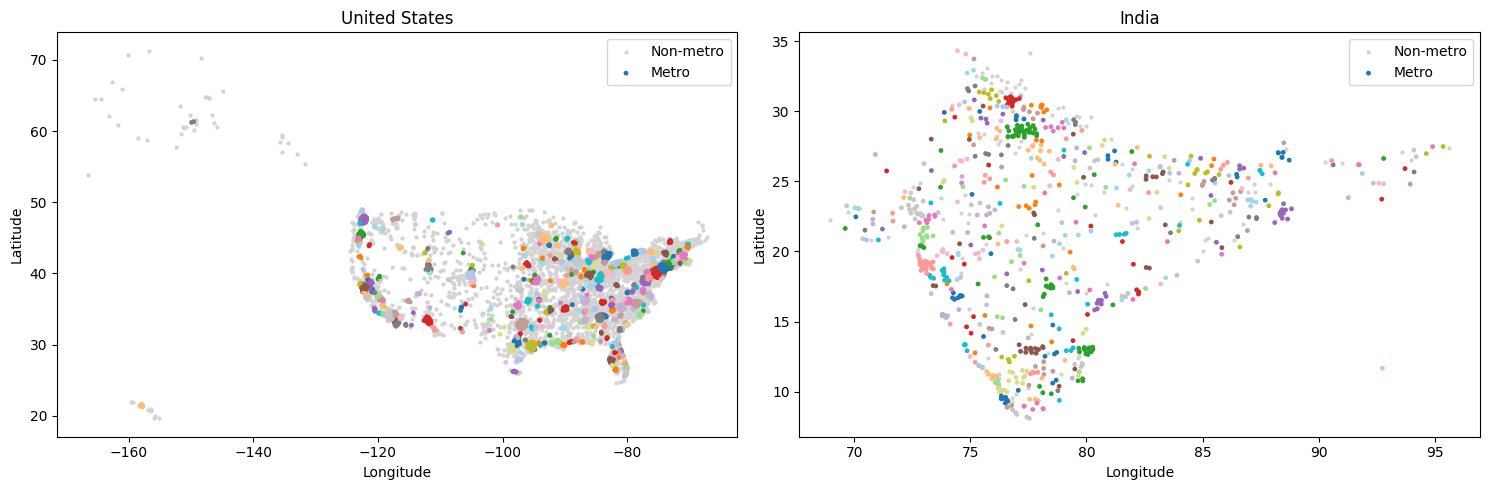

In [38]:
u = result[result.country_key.eq('united states')].copy()
print('Final model vs noisy US labels:')
display(pd.Series(agreement(u)).round(3).to_frame('value'))
t = u.msa.fillna('').str.strip(); known = t.ne('')
official_metro = known & ~t.str.contains('NONMETROPOLITAN', case=False)
display(pd.crosstab(official_metro[known], u.metro[known], rownames=['Official metro'], colnames=['Our metro']))

# (a) Large official MSAs stay whole: share of each MSA's cities that land in our largest matching metro.
big = u[official_metro].groupby('msa').population.sum().sort_values(ascending=False).head(10).index
whole = []
for m in big:
    s = u[u.msa.eq(m)]
    vc = s['Your MSA'].value_counts()
    whole.append({'official MSA': m, 'cities': len(s), 'our main metro': vc.index[0],
                  'share in main metro': vc.iloc[0]/len(s),
                  'fixed-40km pieces': fixed.loc[fixed.msa.eq(m) & fixed.metro, 'Your MSA'].nunique()})
display(pd.DataFrame(whole).round(2))

# (b) Noisy labels corrected by geography: an official *non-metro* label for another state,
#     while our model places the city inside a nearby metro.
abbr_of = u.state_key.map(US_ABBR)
label_state = t.str.extract(r'^([A-Z]{2}) NONMETROPOLITAN', expand=False)
wrong_state = label_state.notna() & label_state.ne(abbr_of) & u.metro
print('Official non-metro labels that name a different state, where we assign a metro:', int(wrong_state.sum()))
display(u[wrong_state].sort_values('population', ascending=False)[['city', 'state', 'population', 'msa', 'Your MSA']].head(10))

# (c) Rural upstate New York stays non-metro, grouped into named regions.
ny = u[u.state_key.eq('new york') & u.latitude.gt(42.3)]
print('Upstate NY (lat > 42.3):', ny['Area Type'].value_counts().to_dict())
display(ny[~ny.metro]['Your MSA'].value_counts().head(10).to_frame('cities'))

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
for ax, country in zip(axes, ['united states', 'india']):
    z = result[result.country_key.eq(country) & result.geo_valid]
    ax.scatter(z[~z.metro].longitude, z[~z.metro].latitude, s=4, c='lightgray', label='Non-metro')
    m = z[z.metro]
    ax.scatter(m.longitude, m.latitude, c=pd.factorize(m['Your MSA'])[0] % 20, cmap='tab20', s=6, label='Metro')
    ax.set(title=country.title(), xlabel='Longitude', ylabel='Latitude'); ax.legend()
plt.tight_layout(); plt.show()

## 6. Export and verification

In [39]:
mapped = cleaner.rows.merge(result[['model_id', 'Your MSA', 'Area Type', 'metro', 'seed', 'anchor_distance_km']],
                            on='model_id', how='left', validate='many_to_one').sort_values('row_id')
final = mapped[['city', 'state', 'latitude', 'longitude', 'population', 'msa', 'Your MSA']].rename(columns={
    'city': 'City', 'state': 'State', 'latitude': 'Latitude', 'longitude': 'Longitude',
    'population': 'Population', 'msa': 'Traditional MSA'})
if final.Population.dropna().mod(1).eq(0).all():
    final['Population'] = final.Population.astype('Int64')
assert len(final) == len(cleaner.rows)
assert final['Your MSA'].notna().all()
assert (result.loc[result.geo_valid, 'Area Type'] != 'Review').all()
# Non-seed members never sit beyond max_km from their anchor.
assert result.loc[result.metro & ~result.seed, 'anchor_distance_km'].le(80 + 1e-9).all()
# Synthetic checks: satellite joins; distant small town stays rural; cross-border town
# cannot join another country's metro; two large cities 300 km apart stay separate.
toy = pd.DataFrame({'city': ['Core', 'Satellite', 'Rural', 'Border', 'Far'], 'state': ['s']*5,
    'country': ['a', 'a', 'a', 'b', 'a'], 'latitude': [0, 0, 0, 0, 0], 'longitude': [0, .1, 2, .1, 2.7],
    'population': [100000, 1000, 1000, 1000, 80000], 'msa': [None]*5})
toy.to_csv('synthetic_check.csv', index=False)
tr = processor.metros(DataCleaningAPI().clean('synthetic_check.csv'))
Path('synthetic_check.csv').unlink()
assert tr.metro.tolist() == [True, True, False, False, True]
assert tr['Your MSA'].iloc[0] == tr['Your MSA'].iloc[1] != tr['Your MSA'].iloc[4]

final.to_csv(OUTPUT, index=False)
mapped.to_csv('msa_diagnostics.csv', index=False)
country_summary.to_csv('country_summary.csv')
print('Saved:', OUTPUT.resolve(), 'Rows:', len(final))
print('Metro entities:', result.loc[result.metro, 'Your MSA'].nunique(),
      '| Non-metro regions:', result.loc[~result.metro & result.geo_valid, 'Your MSA'].nunique())
display(final.head(12))

type of bad_pop: <class 'pandas.core.series.Series'>, shape: (5,), sum: 0, bad_pop: 0    False
1    False
2    False
3    False
4    False
Name: population, dtype: bool
Saved: /Users/garimajain/Documents/GitHub/MSA-Assessment/msa_output.csv Rows: 25410
Metro entities: 3109 | Non-metro regions: 2647


,City,State,Latitude,Longitude,Population,Traditional MSA,Your MSA
0,mahopac,new york,41.37232,-73.73346,8369,New York-Northern New Jersey-Long Island NY-NJ...,"New York City, NY-NJ-CT Metro"
1,seven hills,ohio,41.39533,-81.67624,11690,NaN,"Cleveland, OH Metro"
2,new martinsville,west virginia,39.64452,-80.85760,5218,WV NONMETROPOLITAN AREA,Non-metro WV – Wheeling area
3,sint anthonis,north brabant,51.62667,5.88194,3340,NaN,"Nijmegen–Arnhem–Oss, Netherlands Metro"
4,machali,o higgins region,-34.18082,-70.64933,27595,NaN,"Rancagua, Chile Metro"
5,jankowice,silesia,50.00090,18.98901,2840,NaN,"Katowice–Gliwice–Bytom, Poland Metro"
6,jacksonville,oregon,42.31346,-122.96699,2883,Jacksonville FL MSA,"Medford, OR Metro"
7,fjerritslev,north denmark,57.08822,9.26622,3332,NaN,"Non-metro North Denmark, Denmark – Thisted area"
8,palmanova,balearic islands,39.52470,2.53922,7040,NaN,"Palma, Spain Metro"
9,astorga,castille and leon,42.45879,-6.05601,12078,NaN,"Non-metro Castille And Leon, Spain – Benavente..."
